In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from src.db import query

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

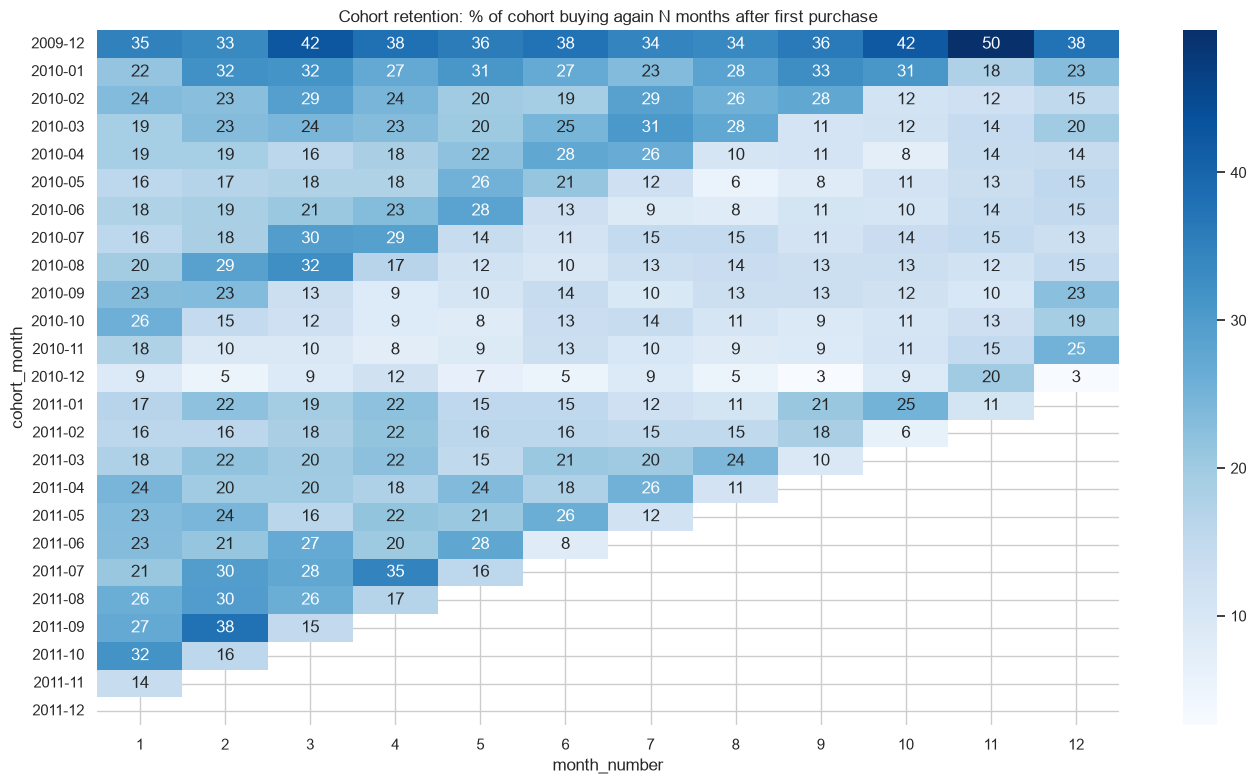

In [2]:
ret = query("SELECT cohort_month, month_number, retention_pct FROM gold.vw_cohort_retention")
pivot = ret.pivot(index="cohort_month", columns="month_number", values="retention_pct")
pivot.index = pd.to_datetime(pivot.index).strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot.loc[:, 1:12], annot=True, fmt=".0f", cmap="Blues", ax=ax)
ax.set_title("Cohort retention: % of cohort buying again N months after first purchase")
plt.tight_layout()
plt.show()

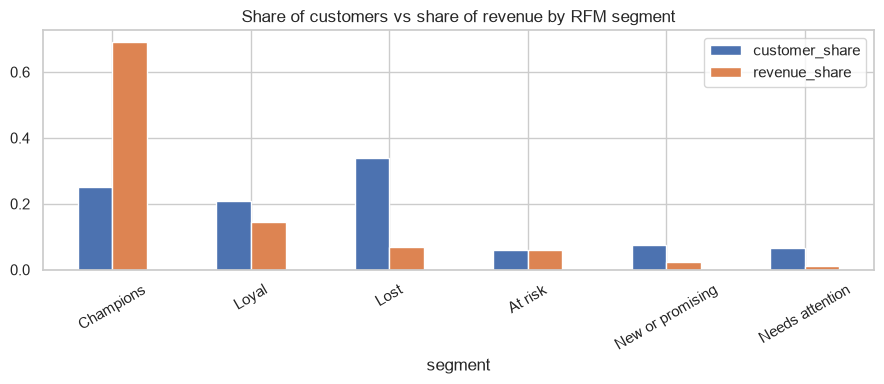

,segment,customers,revenue,customer_share,revenue_share
1,Champions,1470,"11,801,867.73",0.25,0.69
3,Loyal,1213,"2,446,692.67",0.21,0.14
2,Lost,1987,"1,184,849.26",0.34,0.07
0,At risk,355,"1,035,012.63",0.06,0.06
5,New or promising,441,"394,850.30",0.08,0.02
4,Needs attention,386,"204,758.28",0.07,0.01


In [3]:
rfm = query("""
SELECT segment, COUNT(*) AS customers, SUM(monetary) AS revenue
FROM gold.vw_rfm GROUP BY segment
""")
rfm["customer_share"] = rfm["customers"] / rfm["customers"].sum()
rfm["revenue_share"] = rfm["revenue"] / rfm["revenue"].sum()
rfm = rfm.sort_values("revenue_share", ascending=False)

rfm.set_index("segment")[["customer_share", "revenue_share"]].plot(kind="bar", figsize=(9, 4))
plt.title("Share of customers vs share of revenue by RFM segment")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
rfm

## Findings
- Retention does not decay smoothly: customers return in seasonal waves (Oct-Nov peaks). The Dec 2009 cohort is inflated by customers who joined before the data starts.
- Champions are 25% of customers and 69% of revenue; Lost customers are 34% of customers and 7% of revenue.
- At the 1 Mar 2011 snapshot, 75% of customers with a single purchase day in the last 180 days churned, versus 42% of repeat buyers (chi-square p ≈ 2e-85). This is an association, not proof that repeat purchasing prevents churn.
- Implication for modeling: frequency and recency features should be strong, and the snapshot month matters.

In [4]:
# Hypothesis test: is churn independent of purchase frequency?
# Snapshot 2011-03-01, 180-day lookback, 90-day horizon.
snap = query("""
WITH active AS (
    SELECT customer_key, COUNT(*) AS purchase_days
    FROM gold.vw_customer_orders
    WHERE order_date >= DATE '2011-03-01' - 180 AND order_date < DATE '2011-03-01'
    GROUP BY customer_key
)
SELECT a.customer_key, a.purchase_days,
       NOT EXISTS (
           SELECT 1 FROM gold.vw_customer_orders o
           WHERE o.customer_key = a.customer_key
             AND o.order_date >= DATE '2011-03-01'
             AND o.order_date <  DATE '2011-03-01' + 90
       ) AS churned
FROM active a
""")
snap["group"] = snap["purchase_days"].apply(lambda n: "1 purchase day" if n == 1 else "2+ purchase days")

table = pd.crosstab(snap["group"], snap["churned"])
chi2, p, _, _ = chi2_contingency(table)
print(table)
print()
print(snap.groupby("group")["churned"].mean().rename("churn_rate"))
print(f"\nchi-square p-value: {p:.2e}")

churned           False  True 
group                         
1 purchase day      395   1198
2+ purchase days   1019    726

group
1 purchase day     0.75
2+ purchase days   0.42
Name: churn_rate, dtype: float64

chi-square p-value: 1.98e-85
